In [26]:
import pandas as pd
import numpy as np

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()
df.columns


Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [27]:
df.shape
df.info()
df.describe()
df.describe(include='object')

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25052\2223021343.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [28]:
df['TotalCharges'].unique()

<ArrowStringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',
 ...
 '2625.25', '6886.25',  '1495.1',   '743.3',  '1419.4',  '1990.5',  '7362.9',
  '346.45',   '306.6',  '6844.5']
Length: 6531, dtype: str

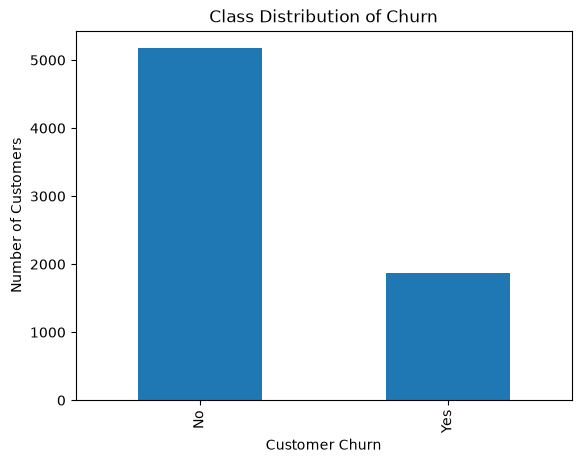

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [29]:
import matplotlib.pyplot as plt

df['Churn'].value_counts().plot(kind='bar')

plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.title("Class Distribution of Churn")
plt.show()

df['Churn'].value_counts()
df['Churn'].value_counts(normalize=True)*100


In [30]:
print(df['Churn'].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [31]:
df.isnull().sum()
(df.isnull().sum()/len(df))*100

customerID          0.0
gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64

In [32]:
df.duplicated().sum()

np.int64(0)

In [33]:
df['TotalCharges'].unique()

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)
df['TotalCharges'].dtype

dtype('float64')

In [34]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [35]:
df.isnull().sum()

(df.isnull().sum()/len(df))*100

customerID          0.000000
gender              0.000000
SeniorCitizen       0.000000
Partner             0.000000
Dependents          0.000000
tenure              0.000000
PhoneService        0.000000
MultipleLines       0.000000
InternetService     0.000000
OnlineSecurity      0.000000
OnlineBackup        0.000000
DeviceProtection    0.000000
TechSupport         0.000000
StreamingTV         0.000000
StreamingMovies     0.000000
Contract            0.000000
PaperlessBilling    0.000000
PaymentMethod       0.000000
MonthlyCharges      0.000000
TotalCharges        0.156183
Churn               0.000000
dtype: float64

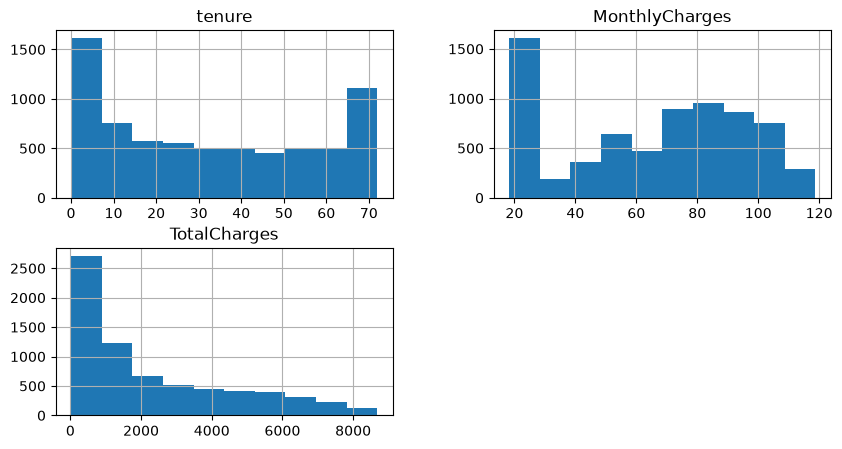

In [36]:
import seaborn as sns

numeric = ['tenure',
           'MonthlyCharges',
           'TotalCharges']


df[numeric].hist(figsize=(10,5))

plt.show()

In [37]:
df[numeric].skew()

tenure            0.239540
MonthlyCharges   -0.220524
TotalCharges      0.961642
dtype: float64

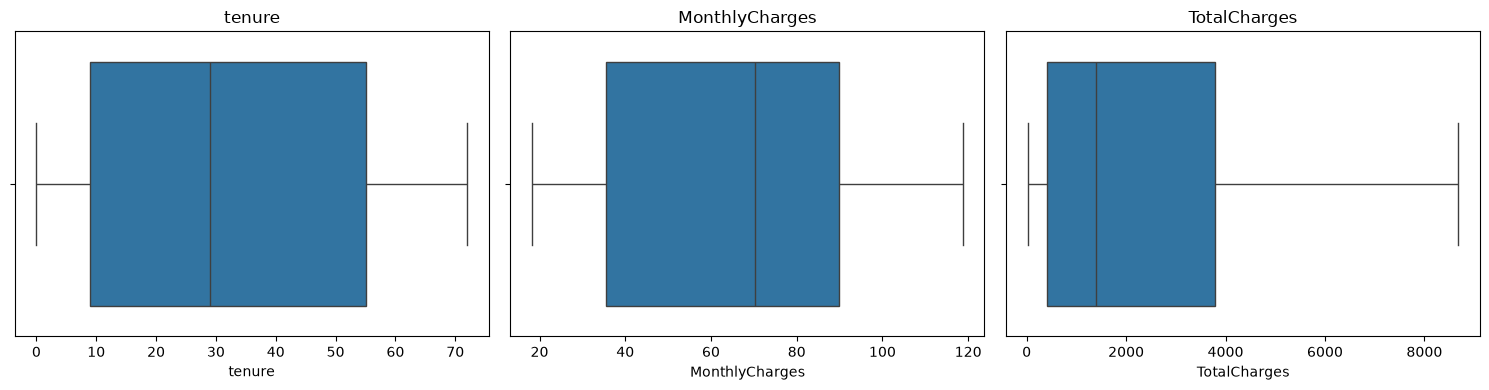

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric = ['tenure', 'MonthlyCharges', 'TotalCharges']

plt.figure(figsize=(15, 4))

for i, col in enumerate(numeric, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

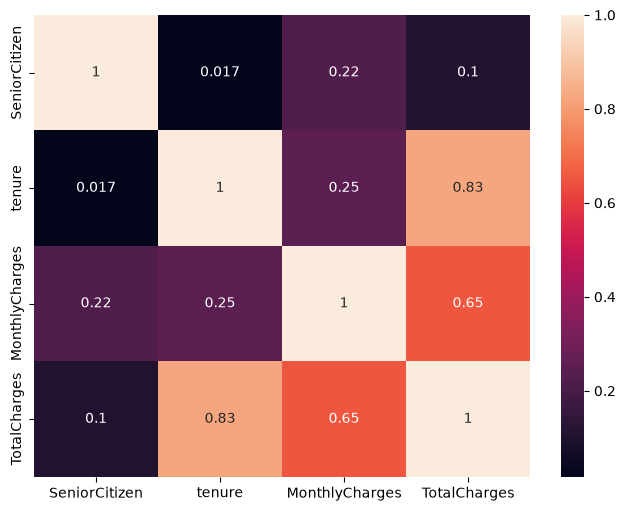

In [39]:
df.corr(numeric_only=True)

plt.figure(figsize=(8,6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True
)

plt.show()

In [40]:
## Categorical Feature Analysis

## Categorical variables were analysed to understand feature composition and identify preprocessing requirements. Since machine learning algorithms require numerical input, these features will require encoding before model training.

In [41]:
categorical = df.select_dtypes(include='object').columns

categorical

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25052\2157510181.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include='object').columns


Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')

In [42]:
for col in categorical:
    print("\n", col)
    print(df[col].value_counts())


 customerID
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

 gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

 Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

 Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

 PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

 MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

 InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

 OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

 OnlineBackup
OnlineBackup
No                     3088
Yes                

In [43]:
## Noise and Irrelevant Features

# Feature investigation was performed to identify attributes that may not contribute meaningful predictive information. Identifier variables such as customerID may introduce noise because they uniquely identify customers but do not represent behavioural patterns.

df.nunique().sort_values()
df['customerID'].nunique()

7043

In [44]:
## Class Imbalance Analysis

#The target variable distribution was examined because imbalance can influence classification model performance.

df['Churn'].value_counts()

df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [45]:
categorical = df.select_dtypes(include='object').columns
categorical

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25052\2105902023.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include='object').columns


Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')

In [46]:
numeric = df.select_dtypes(include=['int64','float64']).columns
numeric
df[['SeniorCitizen','tenure','MonthlyCharges','TotalCharges']].describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [47]:
df.drop('customerID', axis=1)
df[['customerID']].head()


,customerID
0,7590-VHVEG
1,5575-GNVDE
2,3668-QPYBK
3,7795-CFOCW
4,9237-HQITU


In [48]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE   # pip install imbalanced-learn

df = df.drop('customerID', axis=1)                    # assign it back
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})
X, y = df.drop('Churn', axis=1), df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat = X.select_dtypes(include='object').columns.tolist()

prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), num),
    ('cat', OneHotEncoder(sparse_output=False), cat)
], remainder='passthrough')          # keeps SeniorCitizen

X_train_p = prep.fit_transform(X_train)   # fit on train only
X_test_p  = prep.transform(X_test)
print(X_train.shape, '->', X_train_p.shape)          # SCREENSHOT 1

X_res, y_res = SMOTE(random_state=42).fit_resample(X_train_p, y_train)
print(y_train.value_counts(), y_res.value_counts())  # SCREENSHOT 2

pca = PCA().fit(X_train_p)
cum = pca.explained_variance_ratio_.cumsum()
print((cum < 0.95).sum() + 1, "components for 95% variance")  # SCREENSHOT 3


C:\Users\ASUS\AppData\Local\Temp\ipykernel_25052\2204588924.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat = X.select_dtypes(include='object').columns.tolist()


(5634, 19) -> (5634, 45)
Churn
0    4139
1    1495
Name: count, dtype: int64 Churn
0    4139
1    4139
Name: count, dtype: int64
18 components for 95% variance
